# Day 1 — Data Exploration and Quality Checks


## 1. Import libraries and locate the project

We set up table and chart libraries and find the project folders using relative paths.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd().parent.parent]
PROJECT_ROOT=next((p.resolve() for p in candidates if (p/'data'/'raw').exists()),Path.cwd().resolve())
RAW_DIR=PROJECT_ROOT/'data'/'raw'; PROCESSED_DIR=PROJECT_ROOT/'data'/'processed'; REPORTS_DIR=PROJECT_ROOT/'reports'
PROCESSED_DIR.mkdir(parents=True,exist_ok=True); REPORTS_DIR.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid')
print('Project root:',PROJECT_ROOT)


Project root: /home/nineleaps-admin/uber-eats-intelligence


## 2. Load all seven datasets

Loading every table confirms the expected files are available and lets us compare their sizes.

In [2]:
names=['customers','restaurants','orders','deliveries','drivers','reviews','payments']
data={name:pd.read_csv(RAW_DIR/f'{name}.csv') for name in names}
for name,df in data.items(): print(f'{name}: {df.shape[0]:,} rows, {df.shape[1]} columns')
display(data['orders'].head())


customers: 2,000 rows, 6 columns
restaurants: 100 rows, 6 columns
orders: 10,000 rows, 8 columns
deliveries: 8,808 rows, 10 columns
drivers: 500 rows, 5 columns
reviews: 5,968 rows, 8 columns
payments: 10,000 rows, 6 columns


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,number_of_items,order_status,payment_method
0,100001,1891,74,2025-11-14 22:14:00,165.09,2,Completed,UPI
1,100002,1669,20,2025-11-13 00:39:00,369.44,4,Completed,UPI
2,100003,107,54,2025-01-04 01:42:00,349.26,7,Completed,UPI
3,100004,307,69,2025-09-05 16:56:00,379.08,7,Completed,Card
4,100005,800,20,2025-12-28 17:57:00,1343.82,7,Completed,Card


**Observation:** Check the printed shapes and sample rows. If a file is missing, rerun the generator. Next we check column types and dates.

## 3. Column names and data types

Types help distinguish IDs, measures, categories, and timestamps.

In [3]:
for name,df in data.items():
    print('\n'+name.upper())
    display(pd.DataFrame({'column':df.columns,'dtype':df.dtypes.astype(str).values}))
for name,col in [('customers','signup_date'),('orders','order_timestamp'),('reviews','review_timestamp'),('payments','payment_timestamp')]:
    data[name][col]=pd.to_datetime(data[name][col],errors='coerce')



CUSTOMERS


,column,dtype
0,customer_id,int64
1,age,int64
2,gender,str
3,city,str
4,signup_date,str
5,membership_type,str



RESTAURANTS


,column,dtype
0,restaurant_id,int64
1,restaurant_name,str
2,restaurant_category,str
3,restaurant_rating,float64
4,average_preparation_time,float64
5,city,str



ORDERS


...

,column,dtype
0,driver_id,int64
1,driver_rating,float64
2,vehicle_type,str
3,experience_years,float64
4,city,str



REVIEWS


,column,dtype
0,review_id,int64
1,order_id,int64
2,customer_id,int64
3,restaurant_id,int64
4,review_text,str
5,rating,int64
6,sentiment_label,str
7,review_timestamp,str



PAYMENTS


,column,dtype
0,payment_id,int64
1,order_id,int64
2,payment_method,str
3,payment_amount,float64
4,payment_status,str
5,payment_timestamp,str


**Observation:** Confirm timestamp columns are parsed as dates. Next we inspect missing values and duplicates.

## 4. Missing values and duplicates

Missing measurements can be acceptable in some situations, but missing identifiers and duplicate keys can damage joins.

In [4]:
missing=[]; duplicates=[]
keys={'customers':'customer_id','restaurants':'restaurant_id','drivers':'driver_id','orders':'order_id','deliveries':'delivery_id','reviews':'review_id','payments':'payment_id'}
for name,df in data.items():
    missing.append({'dataset':name,'missing_cells':int(df.isna().sum().sum()),'columns_with_missing':int(df.isna().any().sum())})
    duplicates.append({'dataset':name,'duplicate_rows':int(df.duplicated().sum()),'duplicate_primary_keys':int(df[keys[name]].duplicated().sum())})
display(pd.DataFrame(missing)); display(pd.DataFrame(duplicates))


,dataset,missing_cells,columns_with_missing
0,customers,0,0
1,restaurants,0,0
2,orders,0,0
3,deliveries,0,0
4,drivers,0,0
5,reviews,0,0
6,payments,0,0


,dataset,duplicate_rows,duplicate_primary_keys
0,customers,0,0
1,restaurants,0,0
2,orders,0,0
3,deliveries,0,0
4,drivers,0,0
5,reviews,0,0
6,payments,0,0


**Observation:** The generator should produce unique primary keys. Some datasets are naturally smaller because not every order results in a delivery or review.

## 5. Foreign-key relationship checks

These checks confirm that IDs in child tables refer to rows in parent tables.

In [5]:
o=data['orders']; d=data['deliveries']; r=data['reviews']; p=data['payments']
checks={'order customer IDs valid':o.customer_id.isin(data['customers'].customer_id).all(),'order restaurant IDs valid':o.restaurant_id.isin(data['restaurants'].restaurant_id).all(),'delivery order IDs valid':d.order_id.isin(o.order_id).all(),'delivery driver IDs valid':d.driver_id.isin(data['drivers'].driver_id).all(),'review order IDs valid':r.order_id.isin(o.order_id).all(),'payment order IDs valid':p.order_id.isin(o.order_id).all()}
display(pd.DataFrame({'check':checks.keys(),'passed':checks.values()}))


,check,passed
0,order customer IDs valid,True
1,order restaurant IDs valid,True
2,delivery order IDs valid,True
3,delivery driver IDs valid,True
4,review order IDs valid,True
5,payment order IDs valid,True


**Observation:** All checks should pass. If a relationship fails, fix the source data before modeling.

## 6. Descriptive statistics

Summary statistics help identify typical values and unexpected ranges.

In [6]:
display(o[['order_amount','number_of_items']].describe().round(2))
display(data['restaurants'][['restaurant_rating','average_preparation_time']].describe().round(2))
display(d[['delivery_distance_km','delivery_time_minutes','preparation_time_minutes','tip_amount']].describe().round(2))


,order_amount,number_of_items
count,10000.00,10000.00
mean,643.31,4.53
std,314.91,2.30
min,120.00,1.00
25%,409.24,3.00
50%,583.45,5.00
75%,809.08,7.00
max,2500.00,8.00


,restaurant_rating,average_preparation_time
count,100.00,100.00
mean,3.93,26.63
std,0.55,6.41
min,2.71,10.00
25%,3.57,22.98
50%,3.94,26.95
75%,4.29,30.30
max,5.00,49.10


,delivery_distance_km,delivery_time_minutes,preparation_time_minutes,tip_amount
count,8808.00,8808.00,8808.00,8808.00
mean,4.60,39.06,26.02,44.91
std,3.12,14.97,7.03,30.20
min,0.50,12.00,8.00,3.27
25%,2.30,28.40,21.20,22.78
50%,3.90,36.90,26.00,37.16
75%,6.13,47.30,30.72,59.39
max,20.00,110.00,52.60,250.00


**Observation:** Compare the minimum, maximum, median, and average values. These are synthetic measurements, not real company data.

## 7. Order status and monthly trend

Order status shows completed versus cancelled orders. Monthly volume provides a first look at variation over time.

,orders
status,
Completed,9079
Cancelled,921


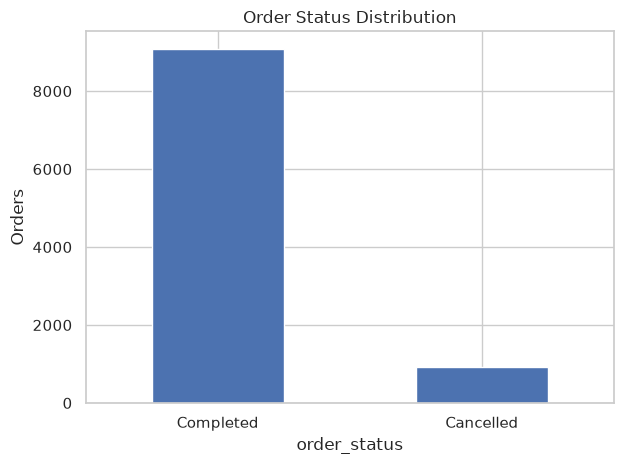

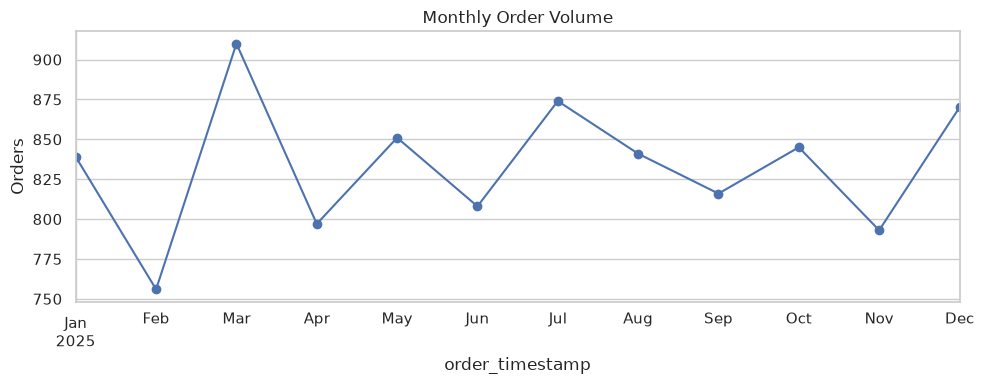

In [7]:
status=o.order_status.value_counts(); display(status.rename_axis('status').to_frame('orders'))
status.plot(kind='bar',title='Order Status Distribution',rot=0); plt.ylabel('Orders'); plt.tight_layout(); plt.show()
monthly=o.set_index('order_timestamp').resample('MS').size()
monthly.plot(figsize=(10,4),marker='o',title='Monthly Order Volume'); plt.ylabel('Orders'); plt.tight_layout(); plt.show()


**Observation:** Describe the actual status mix and month-to-month changes. Because the dataset is synthetic, these patterns are only for practice.

## 8. Order amount distribution

A histogram shows the typical order value and any upper tail.

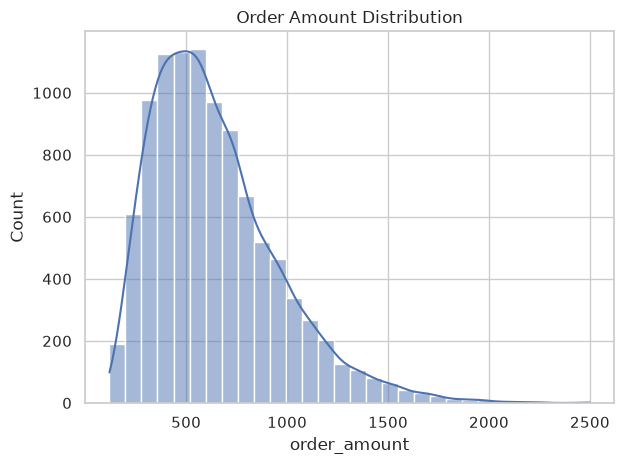

In [8]:
sns.histplot(data=o,x='order_amount',bins=30,kde=True); plt.title('Order Amount Distribution'); plt.tight_layout(); plt.show()
